# 01 — Exploring the xBD dataset

Goal for this phase: understand the data before training anything.

1. How many tiles and buildings are there, and from which disasters?
2. How are the damage labels distributed? (How rare is *destroyed*?)
3. How large are buildings in pixels? (This affects model input size.)
4. What do the before/after pairs look like, especially for Gulf Coast hurricanes?

**Setup:** extract the xBD download so that `data/xbd/tier1/images` and `data/xbd/tier1/labels` exist.
In Colab, mount Drive and set `DATA_ROOT` to the folder on your Drive.

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

import matplotlib.pyplot as plt
import pandas as pd
from src.xbd import DAMAGE_CLASSES, DAMAGE_COLORS, building_table, find_pairs, load_metadata, show_pair

# In Colab: from google.colab import drive; drive.mount('/content/drive')
# then DATA_ROOT = Path('/content/drive/MyDrive/xbd')
DATA_ROOT = PROJECT_ROOT / "data" / "xbd"
SPLIT = "tier1"  # main training set; tier3 has extra training tiles, hold/test are for evaluation
OUTPUT_DIR = PROJECT_ROOT / "outputs"
OUTPUT_DIR.mkdir(exist_ok=True)

## 1. Tiles per disaster

In [2]:
pairs = find_pairs(DATA_ROOT / SPLIT)
missing = pairs[~pairs.pre_image.map(Path.exists) | ~pairs.post_image.map(Path.exists)]
print(f"{len(pairs)} tile pairs, {pairs.disaster.nunique()} disasters, {len(missing)} with missing images")
pairs.disaster.value_counts().to_frame("tiles")

2799 tile pairs, 10 disasters, 0 with missing images


,tiles
disaster,
socal-fire,823
hurricane-michael,343
hurricane-florence,319
hurricane-harvey,319
midwest-flooding,279
hurricane-matthew,238
santa-rosa-wildfire,226
mexico-earthquake,121
palu-tsunami,113


In [3]:
# Disaster type and image metadata from one label file
load_metadata(pairs.post_label.iloc[0])

{'sensor': 'WORLDVIEW03_VNIR',
 'provider_asset_type': 'WORLDVIEW03_VNIR',
 'gsd': 1.4085245,
 'capture_date': '2018-06-22T16:55:40.000Z',
 'off_nadir_angle': 21.97336,
 'pan_resolution': 0.35173947,
 'sun_azimuth': 58.571484,
 'sun_elevation': 71.182274,
 'target_azimuth': 314.29373,
 'disaster': 'guatemala-volcano',
 'disaster_type': 'volcano',
 'catalog_id': '104001003E575F00',
 'original_width': 1024,
 'original_height': 1024,
 'width': 1024,
 'height': 1024,
 'id': 'MjU0NzE2NA.73QhG8U-LJLGkyNS0FB24X8vQS8',
 'img_name': 'guatemala-volcano_00000000_post_disaster.png'}

## 2. Damage label distribution

This takes a minute or two on the full training set because it reads every label file.

In [4]:
buildings = building_table(pairs)
buildings.to_csv(OUTPUT_DIR / f"buildings_{SPLIT}.csv", index=False)

overall = buildings.damage.value_counts().reindex(DAMAGE_CLASSES, fill_value=0)
summary = pd.DataFrame({"buildings": overall, "percent": (100 * overall / overall.sum()).round(2)})
print(f"{len(buildings):,} buildings total")
summary

162,787 buildings total


,buildings,percent
damage,,
no-damage,117426,72.13
minor-damage,14980,9.20
major-damage,14161,8.70
destroyed,13227,8.13
un-classified,2993,1.84


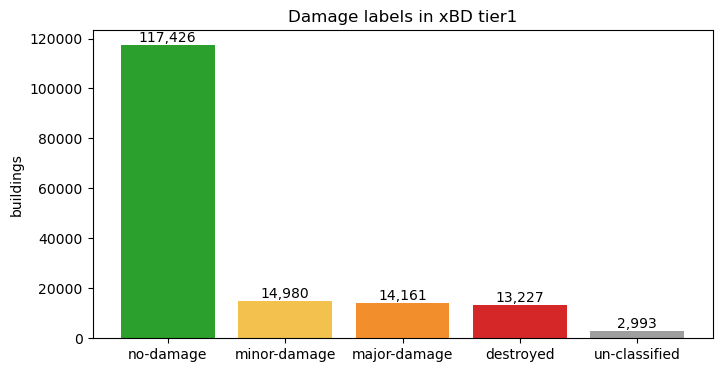

In [5]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(overall.index, overall.values, color=[DAMAGE_COLORS[c] for c in overall.index])
ax.set_ylabel("buildings")
ax.set_title(f"Damage labels in xBD {SPLIT}")
for i, v in enumerate(overall.values):
    ax.text(i, v, f"{v:,}", ha="center", va="bottom")
fig.savefig(OUTPUT_DIR / "damage_distribution.png", dpi=150, bbox_inches="tight")

In [6]:
# Share of each damage level per disaster (rows sum to 100%)
per_disaster = pd.crosstab(buildings.disaster, buildings.damage, normalize="index").reindex(columns=DAMAGE_CLASSES, fill_value=0)
(per_disaster * 100).round(1).sort_values("destroyed", ascending=False)

damage,no-damage,minor-damage,major-damage,destroyed,un-classified
disaster,,,,,
santa-rosa-wildfire,71.7,0.6,0.5,26.8,0.4
palu-tsunami,81.1,0.0,1.8,15.8,1.3
hurricane-matthew,18.0,47.0,14.0,15.4,5.6
socal-fire,82.5,0.8,0.5,12.7,3.6
hurricane-michael,64.3,23.0,8.4,3.3,1.0
guatemala-volcano,74.6,1.1,1.1,2.9,20.3
hurricane-harvey,49.6,11.6,35.8,1.7,1.3
midwest-flooding,92.8,1.7,1.4,0.9,3.3
hurricane-florence,72.7,2.0,19.3,0.8,5.1


## 3. Building size

count    162787.0
mean       1020.7
std        2351.4
min          16.3
5%           87.4
25%         277.4
50%         654.0
75%        1237.5
95%        2655.9
max      398011.6
Name: area_px, dtype: float64


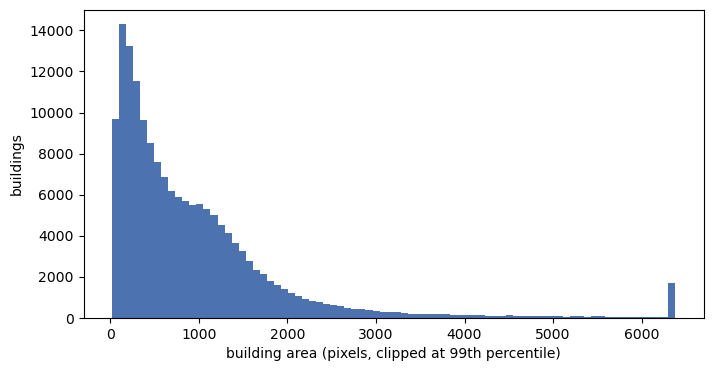

In [7]:
print(buildings.area_px.describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]).round(1))

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(buildings.area_px.clip(upper=buildings.area_px.quantile(0.99)), bins=80, color="#4c72b0")
ax.set_xlabel("building area (pixels, clipped at 99th percentile)")
ax.set_ylabel("buildings")
fig.savefig(OUTPUT_DIR / "building_sizes.png", dpi=150, bbox_inches="tight")

## 4. Before/after examples

xBD's hurricanes are Harvey (Houston/Beaumont, 2017), Michael, Florence and Matthew. The first example below is the Harvey tile with the most destroyed buildings.

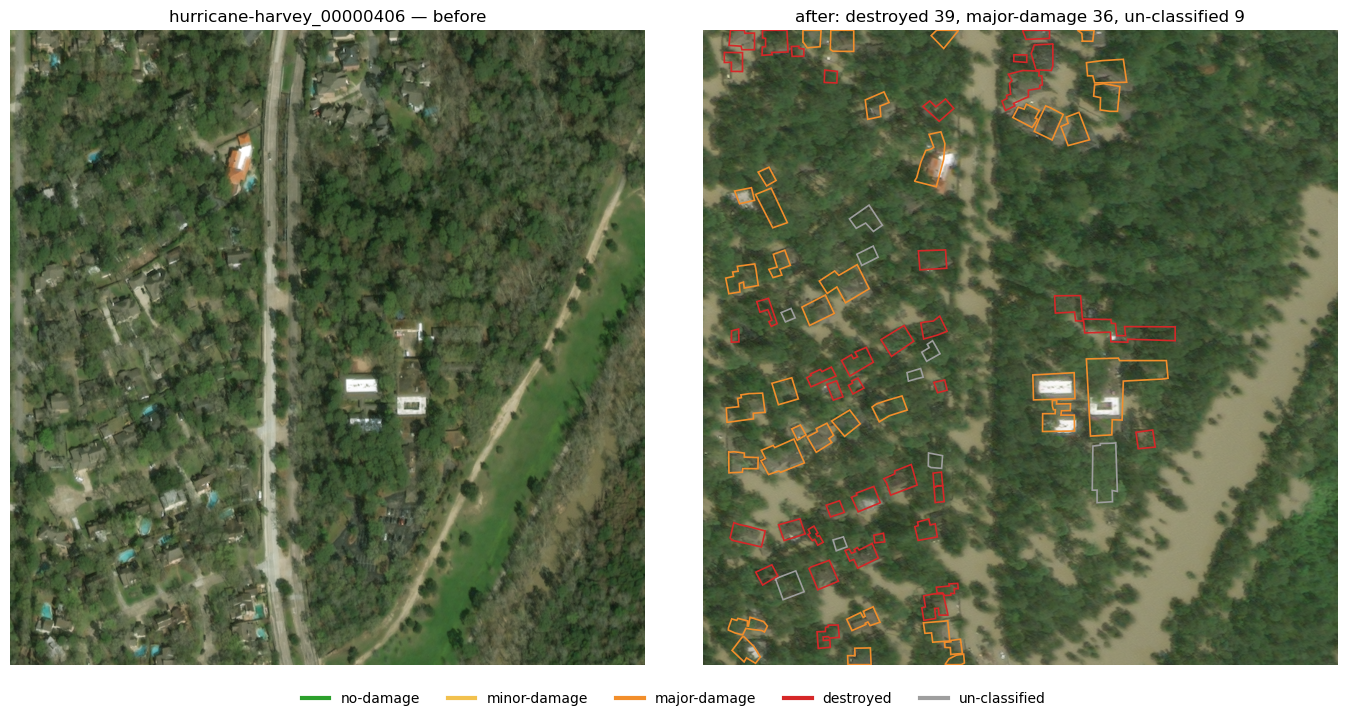

In [8]:
gulf = pairs[pairs.disaster.str.startswith("hurricane-harvey")]
if gulf.empty:
    gulf = pairs[pairs.disaster.str.startswith("hurricane")]

# Tile with the most destroyed buildings among the hurricane tiles
destroyed_per_tile = buildings[buildings.damage == "destroyed"].groupby("tile_id").size()
hurricane_destroyed = destroyed_per_tile.reindex(gulf.tile_id).dropna()
worst_tile = hurricane_destroyed.idxmax() if not hurricane_destroyed.empty else gulf.tile_id.iloc[0]
show_pair(pairs.set_index("tile_id").loc[worst_tile].to_dict() | {"tile_id": worst_tile});

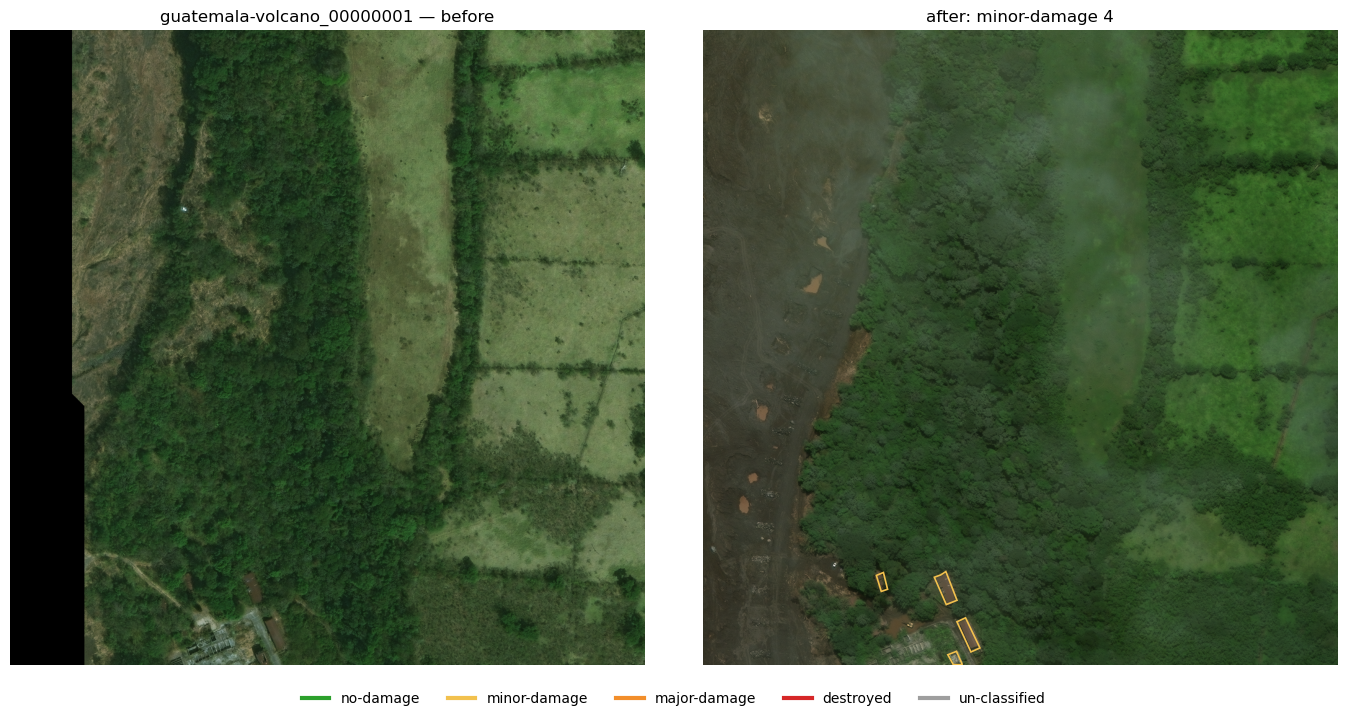

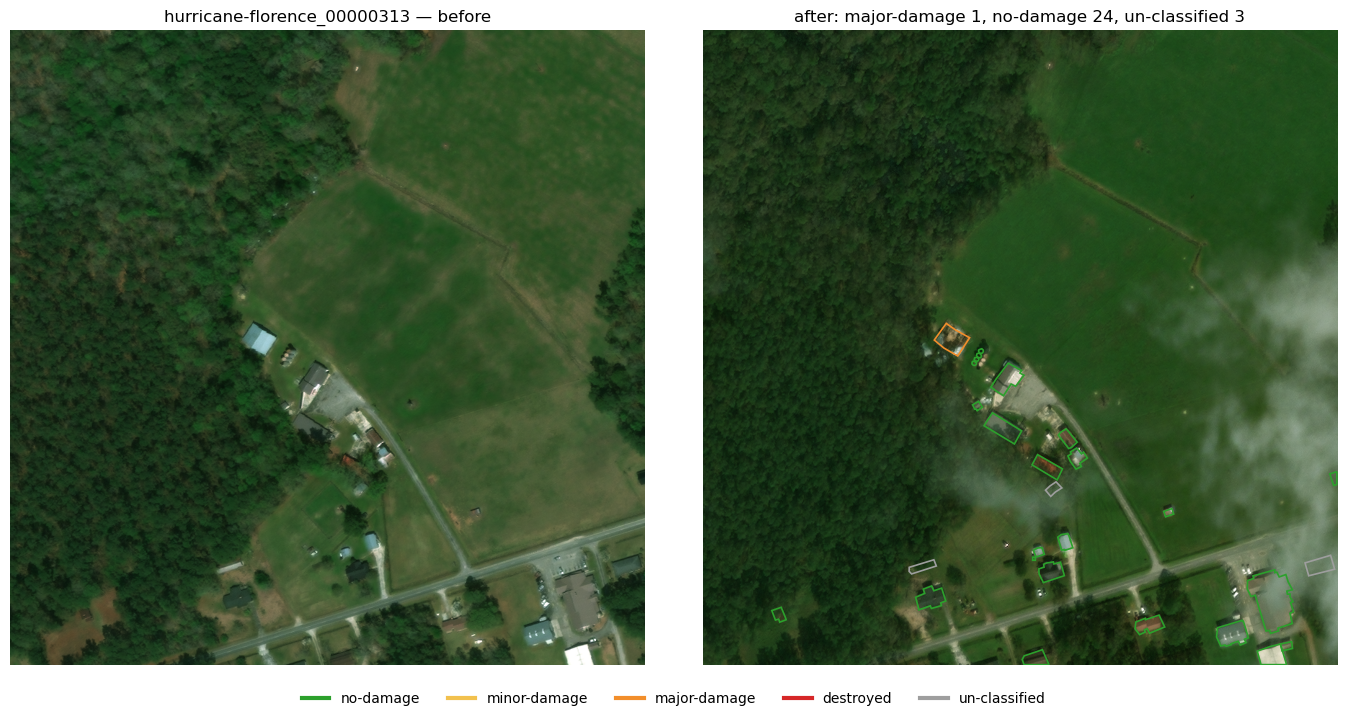

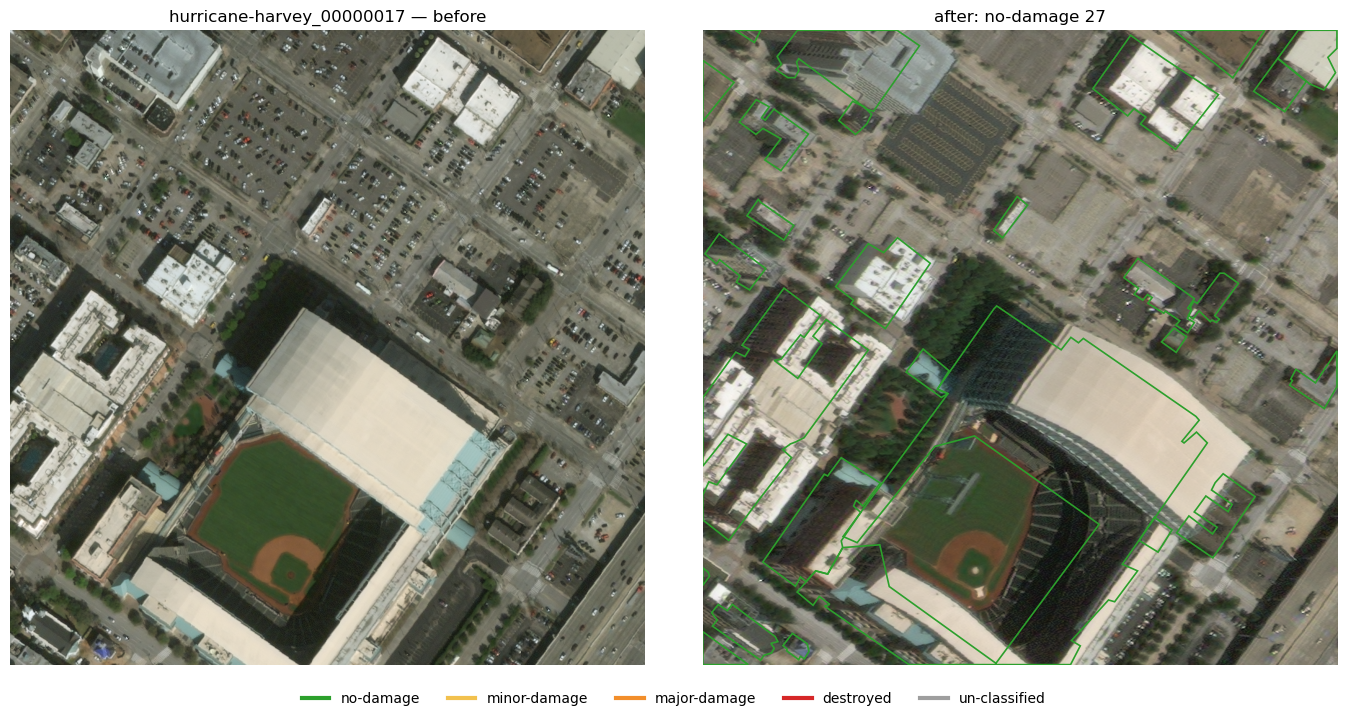

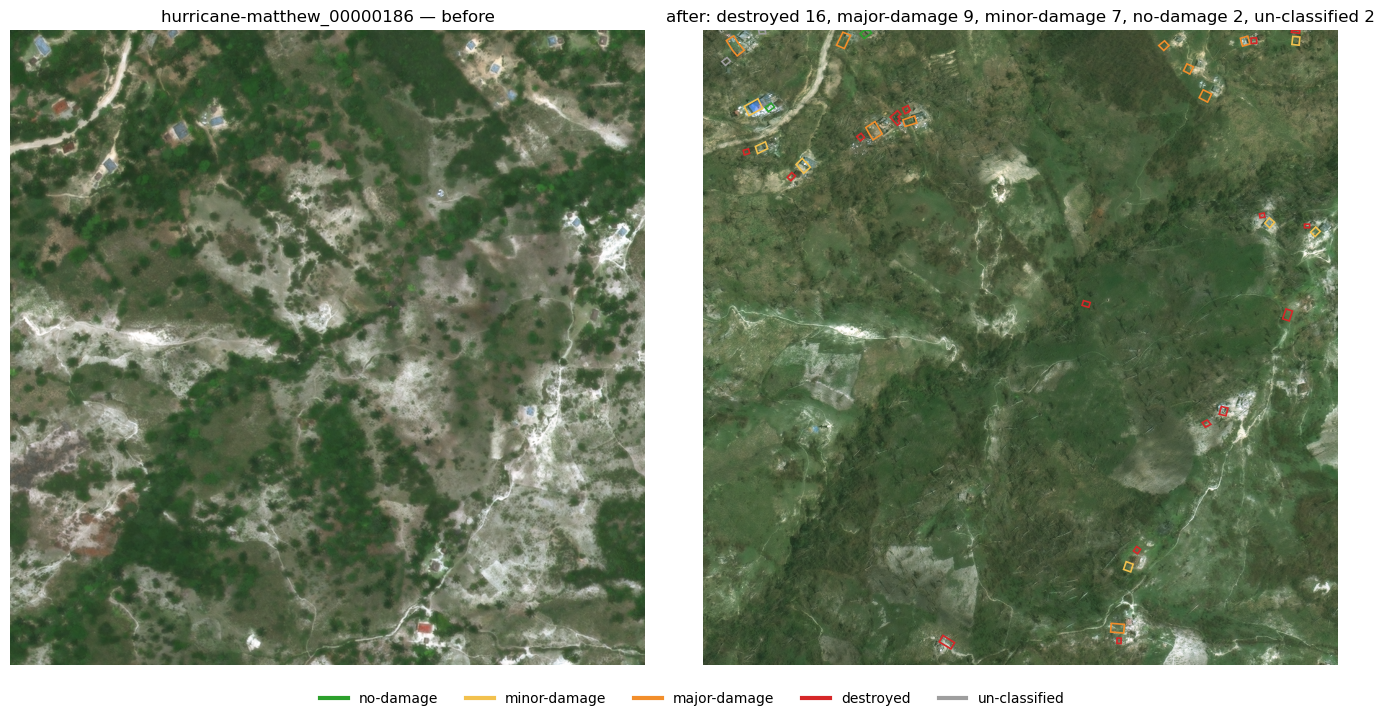

In [9]:
# A few random tiles from different disasters
for _, row in pairs.groupby("disaster").sample(1, random_state=0).head(4).iterrows():
    show_pair(row)

## 5. Notes for the modeling phase

Fill these in after running the notebook:

- Share of *destroyed* buildings: ___ % → need class weighting or oversampling?
- Typical building size: ___ px → are small buildings a risk at lower resolution?
- Disasters with the most damage: ___
- Any label or image problems spotted: ___